
1. LOADING FILES
customers     FOUND
products      FOUND
transactions  FOUND
inventory     FOUND
campaigns     FOUND
customers     rows=  3000  cols=5
products      rows=   250  cols=5
transactions  rows= 18000  cols=10
inventory     rows=  5000  cols=7
campaigns     rows=  1200  cols=8

2. COLUMNS, TYPES, MISSING, DUPLICATES, SAMPLE ROWS (send me this part)

--- customers ---
columns : {'customer_id': 'object', 'region': 'object', 'customer_segment': 'object', 'signup_date': 'object', 'preferred_channel': 'object'}
missing%: none | duplicate rows: 0


,customer_id,region,customer_segment,signup_date,preferred_channel
0,CU00001,West,Returning,2025-04-26,App
1,CU00002,Central,Loyal,2023-06-28,App
2,CU00003,East,Loyal,2023-10-18,App



--- products ---
columns : {'product_id': 'object', 'category': 'object', 'unit_cost': 'float64', 'list_price': 'float64', 'supplier_lead_days': 'int64'}
missing%: none | duplicate rows: 0


,product_id,category,unit_cost,list_price,supplier_lead_days
0,PR0001,Sports,24.30,105.77,12
1,PR0002,Home,108.31,261.50,19
2,PR0003,Sports,223.15,186.62,5



--- transactions ---
columns : {'transaction_id': 'object', 'customer_id': 'object', 'product_id': 'object', 'timestamp': 'object', 'quantity': 'int64', 'unit_price': 'float64', 'discount_pct': 'float64', 'status': 'object', 'channel': 'object', 'payment_method': 'object'}
missing%: none | duplicate rows: 0


...


--- campaigns ---


,count,mean,std,min,25%,50%,75%,max
spend,1200.0,4004.18,2307.54,51.53,2111.14,3932.23,5997.23,7989.61
impressions,1200.0,49558.24,29722.47,117.00,22691.00,50444.50,75646.25,99948.00
clicks,1200.0,5038.08,2902.75,2.00,2482.00,5120.00,7596.00,9994.00
conversions,1200.0,746.18,417.45,0.00,390.00,738.50,1117.00,1496.00



4b. MARGIN CHECK (README warns prices/costs are independent)
using price='list_price', cost='unit_cost'
products where cost > price : 76 of 250
products with margin > 90%  : 12
products with margin < 0%   : 76

5. DETECTING CANCELLATION / RETURN COLUMNS
'status' values: ['Completed', 'Returned', 'Pending', 'Cancelled']
targets found: ['cancelled']
overall cancelled rate: 9.38%

POSSIBLE LEAKAGE COLUMNS (known only after the order, never use as features): ['status', 'is_cancelled']

6. MASTER TABLE (transactions + customers + products)
master shape: (18000, 19) | rows preserved: True
date column 'timestamp': 2025-01-01 00:11:00  ->  2025-12-31 23:53:00
order value column: None | average order value: not found

7. LEAK HUNT: segments whose leak rate is far from the overall rate

--- TOP 12 CANCELLED HOTSPOTS (overall rate 9.38%) ---


,column,segment,orders,rate,lift_vs_avg,extra_leaks,est_money_impact
0,channel,App,7115,0.098,1.041,27.376,NaN
12,region,West,3752,0.100,1.062,21.937,NaN
3,payment_method,Card,3627,0.099,1.058,19.667,NaN
9,region,East,3502,0.099,1.056,18.396,NaN
24,category,Home,3141,0.100,1.062,18.269,NaN
13,customer_segment,At-risk,2742,0.100,1.065,16.709,NaN
17,preferred_channel,App,7143,0.096,1.021,13.749,NaN
11,region,South,3475,0.097,1.034,10.929,NaN
19,preferred_channel,Web,8230,0.095,1.010,7.752,NaN
23,category,Grocery,3150,0.096,1.018,5.425,NaN



8. TIME TREND


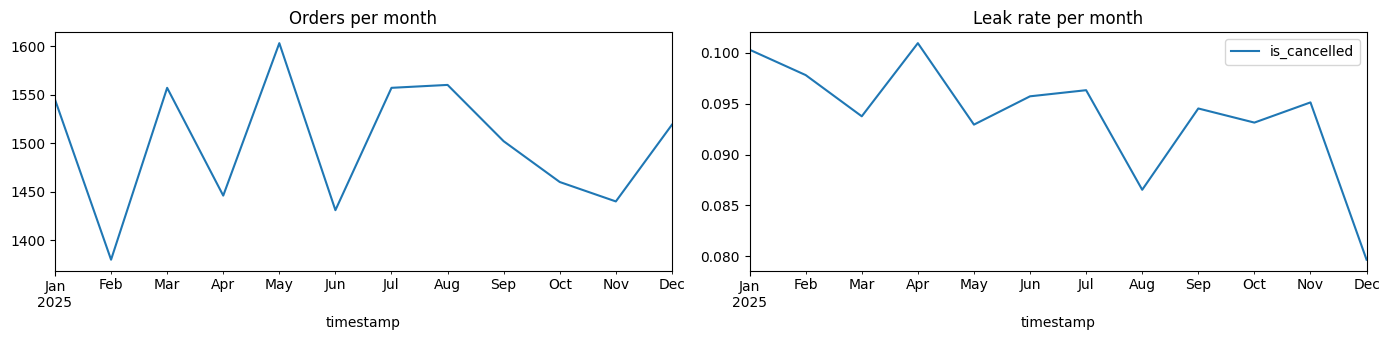


9. INVENTORY (stockout signals)
stock-like columns: ['stock_on_hand', 'stockout_flag']
using 'stock_on_hand': rows at 0 = 10 (0.2%), low (<=10th pct) = 509

zero-stock share by category:


category
Sports         0.005
Home           0.002
Fashion        0.001
Beauty         0.001
Grocery        0.001
Electronics    0.001
Name: zero, dtype: float64


10. CAMPAIGNS (wasted spend)
spend: ['spend'] | clicks: ['clicks'] | conversions: ['conversions']

by channel:


,spend,clicks,conversions,cost_per_conversion,conv_rate
channel,,,,,
Store,945945.23,1185014,165779,5.706,0.140
Social,1049224.57,1248759,185978,5.642,0.149
Email,889045.14,1123992,166542,5.338,0.148
App,1025838.82,1334110,196957,5.208,0.148
Web,894962.32,1153819,180155,4.968,0.156



by category:


,spend,clicks,conversions,cost_per_conversion,conv_rate
category,,,,,
Sports,735675.12,916246,127018,5.792,0.139
Beauty,870069.67,970967,152756,5.696,0.157
Fashion,801837.79,1015438,150801,5.317,0.149
Electronics,820672.69,1073059,154962,5.296,0.144
Grocery,800272.54,1120445,156739,5.106,0.140
Home,776488.27,949539,153135,5.071,0.161


In [3]:
import pandas as pd, numpy as np, os, warnings
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_rows", 80)

def H(t): print("\n" + "="*95 + f"\n{t}\n" + "="*95)

# ---------------------------------------------------------------- 1. LOAD
H("1. LOADING FILES")
BASE = "/kaggle/input/datasets/kushalvuriti/business-money-leak/04_business_money_leak"
need = ["customers", "products", "transactions", "inventory", "campaigns"]
for f in need:
    p = f"{BASE}/{f}.csv"
    print(f"{f:13s} {'FOUND' if os.path.exists(p) else 'MISSING  <-- check path'}")
assert all(os.path.exists(f"{BASE}/{f}.csv") for f in need), "A file is missing, fix BASE path"

cust = pd.read_csv(f"{BASE}/customers.csv");   prod = pd.read_csv(f"{BASE}/products.csv")
txn  = pd.read_csv(f"{BASE}/transactions.csv"); inv  = pd.read_csv(f"{BASE}/inventory.csv")
camp = pd.read_csv(f"{BASE}/campaigns.csv")
tables = dict(customers=cust, products=prod, transactions=txn, inventory=inv, campaigns=camp)
for n, d in tables.items(): print(f"{n:13s} rows={d.shape[0]:6d}  cols={d.shape[1]}")

# ---------------------------------------------------------------- 2. PROFILE
H("2. COLUMNS, TYPES, MISSING, DUPLICATES, SAMPLE ROWS (send me this part)")
for n, d in tables.items():
    print(f"\n--- {n} ---")
    print("columns :", {c: str(t) for c, t in d.dtypes.items()})
    miss = d.isna().mean().mul(100).round(1); miss = miss[miss > 0]
    print("missing%:", miss.to_dict() if len(miss) else "none", "| duplicate rows:", d.duplicated().sum())
    display(d.head(3))

# ---------------------------------------------------------------- 3. INTEGRITY
H("3. KEY INTEGRITY (do the joins work?)")
print("transactions with unknown customer:", (~txn.customer_id.isin(cust.customer_id)).sum())
print("transactions with unknown product :", (~txn.product_id.isin(prod.product_id)).sum())
print("inventory with unknown product    :", (~inv.product_id.isin(prod.product_id)).sum())
print("duplicate transaction ids         :", txn.iloc[:, 0].duplicated().sum(), f"(first column '{txn.columns[0]}' treated as id)")

# ---------------------------------------------------------------- 4. NUMERIC SANITY
H("4. NUMERIC SUMMARY (look for negatives, zeros, huge outliers)")
for n in ["transactions", "products", "inventory", "campaigns"]:
    print(f"\n--- {n} ---"); display(tables[n].describe().T.round(2))

pc = [c for c in prod.columns if "price" in c.lower()]
cc = [c for c in prod.columns if "cost" in c.lower()]
if pc and cc:
    H("4b. MARGIN CHECK (README warns prices/costs are independent)")
    p, c = prod[pc[0]], prod[cc[0]]
    print(f"using price='{pc[0]}', cost='{cc[0]}'")
    print("products where cost > price :", (c > p).sum(), "of", len(prod))
    print("products with margin > 90%  :", (((p - c) / p) > 0.9).sum())
    print("products with margin < 0%   :", (((p - c) / p) < 0).sum())

# ---------------------------------------------------------------- 5. TARGETS
H("5. DETECTING CANCELLATION / RETURN COLUMNS")
targets = {}
for col in txn.columns:
    lc, vals = col.lower(), txn[col].dropna()
    if vals.nunique() <= 12:
        s = vals.astype(str).str.lower()
        if "cancel" in lc and set(vals.unique()) <= {0, 1, True, False}: targets["cancelled"] = txn[col].astype(int)
        elif "return" in lc and set(vals.unique()) <= {0, 1, True, False}: targets["returned"] = txn[col].astype(int)
        elif s.str.contains("cancel").any(): targets["cancelled"] = txn[col].astype(str).str.lower().str.contains("cancel").astype(int); print(f"'{col}' values:", list(vals.unique()))
        elif s.str.contains("return").any(): targets["returned"] = txn[col].astype(str).str.lower().str.contains("return").astype(int); print(f"'{col}' values:", list(vals.unique()))
print("targets found:", list(targets) or "NONE - tell me which column holds the status")
for k, v in targets.items(): txn[f"is_{k}"] = v; print(f"overall {k} rate: {v.mean():.2%}")

leaky = [c for c in txn.columns if any(w in c.lower() for w in ["refund", "return", "cancel", "reason", "status"])]
print("\nPOSSIBLE LEAKAGE COLUMNS (known only after the order, never use as features):", leaky)

# ---------------------------------------------------------------- 6. MASTER TABLE
H("6. MASTER TABLE (transactions + customers + products)")
m = (txn.merge(cust, on="customer_id", how="left", suffixes=("", "_cust"))
        .merge(prod, on="product_id", how="left", suffixes=("", "_prod")))
print("master shape:", m.shape, "| rows preserved:", len(m) == len(txn))
dcols = [c for c in txn.columns if "date" in c.lower() or "time" in c.lower()]
DATE = dcols[0] if dcols else None
if DATE:
    m[DATE] = pd.to_datetime(m[DATE], errors="coerce")
    print(f"date column '{DATE}': {m[DATE].min()}  ->  {m[DATE].max()}")
acols = [c for c in txn.columns if any(w in c.lower() for w in ["amount", "revenue", "total", "sales", "value"])]
AMT = acols[0] if acols else None
print("order value column:", AMT, "| average order value:", round(m[AMT].mean(), 2) if AMT else "not found")

# ---------------------------------------------------------------- 7. WHERE ARE THE LEAKS
H("7. LEAK HUNT: segments whose leak rate is far from the overall rate")
cat = [c for c in m.columns if m[c].dtype == "object" and 2 <= m[c].nunique() <= 25
       and not c.startswith("is_") and c not in leaky]
for t in targets:
    tc, overall = f"is_{t}", m[f"is_{t}"].mean()
    rows = []
    for col in cat:
        g = m.groupby(col)[tc].agg(rate="mean", orders="count")
        g = g[g.orders >= 50]
        for seg, r in g.iterrows():
            extra = (r.rate - overall) * r.orders
            rows.append((col, seg, int(r.orders), r.rate, r.rate / overall, extra,
                         extra * m[AMT].mean() if AMT else np.nan))
    out = pd.DataFrame(rows, columns=["column", "segment", "orders", "rate", "lift_vs_avg", "extra_leaks", "est_money_impact"])
    print(f"\n--- TOP 12 {t.upper()} HOTSPOTS (overall rate {overall:.2%}) ---")
    display(out.sort_values("extra_leaks", ascending=False).head(12).round(3))

# ---------------------------------------------------------------- 8. TIME TREND
H("8. TIME TREND")
if DATE:
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
    m.set_index(DATE).resample("M").size().plot(ax=ax[0], title="Orders per month")
    if targets: m.set_index(DATE)[[f"is_{t}" for t in targets]].resample("M").mean().plot(ax=ax[1], title="Leak rate per month")
    plt.tight_layout(); plt.show()

# ---------------------------------------------------------------- 9. INVENTORY
H("9. INVENTORY (stockout signals)")
scols = [c for c in inv.columns if any(w in c.lower() for w in ["stock", "quantity", "on_hand", "level", "units"])]
print("stock-like columns:", scols)
if scols:
    s = scols[0]
    print(f"using '{s}': rows at 0 = {(inv[s] <= 0).sum()} ({(inv[s] <= 0).mean():.1%}), low (<=10th pct) = {(inv[s] <= inv[s].quantile(.1)).sum()}")
    ij = inv.merge(prod, on="product_id", how="left", suffixes=("", "_p"))
    for c in [c for c in ij.columns if ij[c].dtype == "object" and 2 <= ij[c].nunique() <= 25][:3]:
        print(f"\nzero-stock share by {c}:")
        display(ij.assign(zero=ij[s] <= 0).groupby(c).zero.mean().sort_values(ascending=False).head(6).round(3))

# ---------------------------------------------------------------- 10. CAMPAIGNS
H("10. CAMPAIGNS (wasted spend)")
sp = [c for c in camp.columns if any(w in c.lower() for w in ["spend", "cost", "budget"])]
cl = [c for c in camp.columns if "click" in c.lower()]
cv = [c for c in camp.columns if "conver" in c.lower()]
print("spend:", sp, "| clicks:", cl, "| conversions:", cv)
grp = [c for c in camp.columns if camp[c].dtype == "object" and 2 <= camp[c].nunique() <= 25]
if sp and cl and cv and grp:
    for g in grp[:3]:
        t = camp.groupby(g)[[sp[0], cl[0], cv[0]]].sum()
        t["cost_per_conversion"] = t[sp[0]] / t[cv[0]].replace(0, np.nan)
        t["conv_rate"] = t[cv[0]] / t[cl[0]].replace(0, np.nan)
        print(f"\nby {g}:"); display(t.sort_values("cost_per_conversion", ascending=False).round(3))


In [4]:
# ===================== LEAKLENS: ONE-CELL BUILD (findings + 2 models + exports) =====================
import os, json, warnings, joblib
import numpy as np, pandas as pd
from scipy.stats import chi2_contingency
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 70)
def H(t): print("\n" + "="*95 + f"\n{t}\n" + "="*95)

# ------------------------------------------------------------------ 1. LOAD
H("1. LOAD DATA")
BASE = next(p for p in ["/kaggle/input/datasets/kushalvuriti/business-money-leak/04_business_money_leak",
                        "/mnt/user-data/uploads", "."] if os.path.exists(f"{p}/transactions.csv"))
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "./leaklens_out"
os.makedirs(OUT, exist_ok=True)
cust, prod, txn = (pd.read_csv(f"{BASE}/{f}.csv") for f in ["customers", "products", "transactions"])
inv, camp = pd.read_csv(f"{BASE}/inventory.csv"), pd.read_csv(f"{BASE}/campaigns.csv")
print("data from:", BASE, "\noutput to:", OUT)

# ------------------------------------------------------------------ 2. MASTER TABLE
H("2. MASTER TABLE (revenue, profit, order-time features)")
t = txn.copy(); t["timestamp"] = pd.to_datetime(t.timestamp)
t["revenue"] = t.quantity * t.unit_price * (1 - t.discount_pct)
c2 = cust.copy(); c2["signup_date"] = pd.to_datetime(c2.signup_date)
m = t.merge(c2, on="customer_id", how="left").merge(prod, on="product_id", how="left")
m = m.sort_values("timestamp").reset_index(drop=True)
m["tenure_days"] = (m.timestamp - m.signup_date).dt.days
m["hour"], m["dow"] = m.timestamp.dt.hour, m.timestamp.dt.dayofweek
m["price_ratio"] = m.unit_price / m.list_price
m["below_cost"] = (m.unit_price * (1 - m.discount_pct) < m.unit_cost).astype(int)
m["profit"] = m.revenue - m.quantity * m.unit_cost
for s in ["Cancelled", "Returned", "Pending"]: m[f"is_{s.lower()}"] = (m.status == s).astype(int)
END = m.timestamp.max(); TOTAL_REV = m.revenue.sum()
print(f"orders={len(m)} | order value={TOTAL_REV:,.0f} | period {m.timestamp.min().date()} -> {END.date()}")

# ------------------------------------------------------------------ 3. IS A SEGMENT GAP REAL OR NOISE?
H("3. SIGNIFICANCE TESTS (chi-square + Benjamini-Hochberg correction across ALL tests)")
def bh(p):
    p = np.asarray(p); n = len(p); o = np.argsort(p); adj = np.empty(n); prev = 1.0
    for i in range(n - 1, -1, -1):
        k = o[i]; prev = min(prev, p[k] * n / (i + 1)); adj[k] = prev
    return adj
seg_cols = ["region", "customer_segment", "preferred_channel", "channel", "payment_method", "category", "discount_pct", "quantity", "dow"]
rows = []
for tg in ["is_cancelled", "is_returned"]:
    for col in seg_cols:
        p = chi2_contingency(pd.crosstab(m[col], m[tg]))[1]
        g = m.groupby(col)[tg].agg(["mean", "size"]); top = g["mean"].idxmax()
        rows.append(dict(target=tg, column=col, p=p, top_segment=str(top), top_rate=g.loc[top, "mean"], lift=g.loc[top, "mean"] / m[tg].mean()))
sig = pd.DataFrame(rows); sig["p_adj"] = bh(sig.p); sig["real"] = sig.p_adj < 0.05
display(sig.round(4))
print("tests:", len(sig), "| significant before correction:", int((sig.p < .05).sum()), "| significant after correction:", int(sig.real.sum()))

# ------------------------------------------------------------------ 4. MODEL A: ORDER OUTCOME (trained by us, time split)
H("4. MODEL A: will an order be cancelled / returned? (train Jan-Sep, test Oct-Dec)")
feat_num = ["quantity", "unit_price", "discount_pct", "hour", "dow", "tenure_days", "supplier_lead_days", "unit_cost", "list_price", "price_ratio", "below_cost"]
feat_cat = ["channel", "payment_method", "region", "customer_segment", "preferred_channel", "category"]
X = pd.concat([m[feat_num], pd.get_dummies(m[feat_cat], dtype=int)], axis=1); COLS = list(X.columns)
tr = (m.timestamp < "2025-10-01").values; te = ~tr
rng = np.random.default_rng(0)
def boot_ci(y, p, n=300):
    idx = np.arange(len(y)); out = []
    for _ in range(n):
        b = rng.choice(idx, len(idx)); 
        if y[b].min() != y[b].max(): out.append(roc_auc_score(y[b], p[b]))
    return float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))
def lift_top10(y, p):
    k = int(len(y) * .10); return float(y[np.argsort(-p)[:k]].mean() / y.mean())
metA, lr_models, pred_cols = {}, {}, {}
for tg, nm in [("is_cancelled", "cancel"), ("is_returned", "return")]:
    y = m[tg].values
    seg_rate = m[tr].groupby("category")[tg].mean(); p_seg = m.loc[te, "category"].map(seg_rate).fillna(y[tr].mean()).values
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X[tr], y[tr])
    gb = HistGradientBoostingClassifier(max_depth=3, learning_rate=.05, max_iter=150, random_state=0).fit(X[tr], y[tr])
    res = {"test_rows": int(te.sum()), "test_positive_rate": round(float(y[te].mean()), 4)}
    for name, p in [("baseline_category_rate", p_seg), ("logistic_regression", lr.predict_proba(X[te])[:, 1]), ("gradient_boosting", gb.predict_proba(X[te])[:, 1])]:
        lo, hi = boot_ci(y[te], p)
        res[name] = {"roc_auc": round(roc_auc_score(y[te], p), 3), "auc_95ci": [round(lo, 3), round(hi, 3)],
                     "pr_auc": round(average_precision_score(y[te], p), 3), "lift_top10pct": round(lift_top10(y[te], p), 2)}
    best = max(["logistic_regression", "gradient_boosting"], key=lambda k: res[k]["roc_auc"])
    res["reliable_signal"] = bool(res[best]["auc_95ci"][0] > 0.5)
    res["verdict"] = ("Model beats random with 95% confidence" if res["reliable_signal"] else
                      "NO RELIABLE SIGNAL: AUC interval includes 0.50 (random). Do not use for decisions.")
    metA[nm] = res
    pipe_all = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X, y); lr_models[nm] = pipe_all
    pr = np.zeros(len(m)); pr[tr] = lr.predict_proba(X[tr])[:, 1]; pr[te] = lr.predict_proba(X[te])[:, 1]; pred_cols[nm] = pr
    print(f"\n{nm.upper()}  (test positive rate {res['test_positive_rate']:.1%}) -> {res['verdict']}")
    display(pd.DataFrame({k: res[k] for k in ["baseline_category_rate", "logistic_regression", "gradient_boosting"]}).T)

# ------------------------------------------------------------------ 5. MODEL B: CAMPAIGN ANOMALY DETECTOR
H("5. MODEL B: Isolation Forest on campaigns (trained by us, unsupervised)")
cp = camp.copy()
cp["ctr"] = cp.clicks / cp.impressions; cp["conv_rate"] = cp.conversions / cp.clicks.replace(0, np.nan)
cp["cost_per_conv"] = cp.spend / cp.conversions.replace(0, np.nan)
cp["invalid_funnel"] = ((cp.clicks > cp.impressions) | (cp.conversions > cp.clicks)).astype(int)
fe = pd.DataFrame({"log_spend": np.log1p(cp.spend), "log_cost_per_conv": np.log(cp.cost_per_conv.fillna(cp.cost_per_conv.max())),
                   "ctr": cp.ctr, "conv_rate": cp.conv_rate.fillna(0), "log_impressions": np.log1p(cp.impressions)})
iso = IsolationForest(n_estimators=300, contamination=0.15, random_state=0).fit(fe)
cp["anomaly_score"] = -iso.decision_function(fe); cp["flagged"] = (iso.predict(fe) == -1).astype(int)
med_cpc = cp.cost_per_conv.median(); cp["excess_spend"] = (cp.spend - cp.conversions * med_cpc).clip(lower=0)
z = (fe - fe.median()) / (1.4826 * (fe - fe.median()).abs().median())
why = {"log_spend": "unusually high/low spend", "log_cost_per_conv": "very high cost per conversion", "ctr": "click-through rate impossible or extreme",
       "conv_rate": "conversion rate impossible or extreme", "log_impressions": "unusual impressions"}
cp["why_flagged"] = z.abs().idxmax(axis=1).map(why)
tp = int(((cp.flagged == 1) & (cp.invalid_funnel == 1)).sum())
metB = {"campaigns": len(cp), "flagged": int(cp.flagged.sum()), "impossible_funnel_rows": int(cp.invalid_funnel.sum()),
        "impossible_rows_caught": tp, "recall_on_impossible_rows": round(float(tp / cp.invalid_funnel.sum()), 3),
        "precision_on_impossible_rows": round(float(tp / cp.flagged.sum()), 3), "median_cost_per_conversion": round(float(med_cpc), 2),
        "note": "Sanity check only: impossible-funnel rows (clicks>impressions or conversions>clicks) are a rule-based proxy, not ground truth."}
print(metB); display(cp.sort_values("anomaly_score", ascending=False).head(6)[["campaign_id", "channel", "category", "spend", "clicks", "conversions", "cost_per_conv", "why_flagged"]].round(2))

# ------------------------------------------------------------------ 6. FINDINGS LEDGER
H("6. FINDINGS LEDGER")
findings = []
def add(fid, typ, title, money, conf, verdict, evidence, action, assumptions, metrics=None):
    findings.append(dict(id=fid, type=typ, title=title, money_impact=round(float(money), 0), confidence=conf, verdict=verdict,
                         evidence=evidence, action=action, assumptions=assumptions, metrics=metrics or {}))
# F1 pricing & discounts
below_list = float((m.quantity * (m.list_price - m.unit_price)).sum()); disc = float((m.quantity * m.unit_price * m.discount_pct).sum())
gap_cat = (m.quantity * m.list_price - m.revenue).groupby(m.category).sum().sort_values(ascending=False)
add("F1", "pricing", "Orders sell well below list price and discounts stack on top", below_list + disc, "High (measured)", "REAL (arithmetic from data)",
    [f"Order value is {TOTAL_REV:,.0f} against {float((m.quantity*m.list_price).sum()):,.0f} at list price.",
     f"{(m.price_ratio < .99).mean():.0%} of orders are priced below list (price is 75-100% of list), costing {below_list:,.0f}.",
     f"discount_pct adds a further {disc:,.0f} on top.", f"Largest gap by category: {gap_cat.index[0]} ({gap_cat.iloc[0]:,.0f})."],
    "Review who can set prices below list and cap stacked discounts (price cut + discount_pct).",
    "list_price is treated as the reference price.", {"below_list": round(below_list), "discount": round(disc), "gap_by_category": gap_cat.round(0).to_dict()})
# F2 below cost
done = m[m.status == "Completed"]; neg = done[done.profit < 0]
pp = done.groupby("product_id").profit.sum(); cm = done.groupby("category").apply(lambda g: g.profit.sum() / g.revenue.sum())
add("F2", "margin", "A large share of orders are sold below unit cost", -float(neg.profit.sum()), "Medium (depends on cost data)", "ASSUMPTION-DEPENDENT",
    [f"{m.below_cost.mean():.0%} of all orders sell below unit cost; completed orders with negative profit lose {-neg.profit.sum():,.0f}.",
     f"{int((pp < 0).sum())} of {prod.shape[0]} products have negative total profit; {int((prod.unit_cost > prod.list_price).sum())} have unit cost above list price.",
     f"Lowest category margin: {cm.idxmin()} at {cm.min():.1%} (others up to {cm.max():.1%})."],
    "Check cost and price master data first, then reprice or stop selling the worst products.",
    "README says costs and prices were generated independently, so margins may be unrealistic. Treat as a data-quality and pricing alert, not proven loss.",
    {"loss_products": int((pp < 0).sum()), "worst_products": pp.sort_values().head(5).round(0).to_dict()})
# F3 / F4 cancel & return
for fid, tg, label in [("F3", "is_cancelled", "Cancelled"), ("F4", "is_returned", "Returned")]:
    s = sig[sig.target == tg]; money = float(m.loc[m[tg] == 1, "revenue"].sum()); nm = "cancel" if tg == "is_cancelled" else "return"
    best = s.sort_values("p").iloc[0]
    add(fid, "orders", f"{label} orders ({m[tg].mean():.1%} of orders): no reliable driver found", money,
        "No driver detected in this data", "NOISE (no significant segment)" if not s.real.any() else "REAL (see segments)",
        [f"{int(m[tg].sum())} orders, value {money:,.0f}.", f"{len(s)} segment tests run; {int((s.p < .05).sum())} passed p<0.05 before correction, {int(s.real.sum())} after Benjamini-Hochberg correction.",
         f"Most extreme gap: {best.column}={best.top_segment} at {best.top_rate:.1%} vs {m[tg].mean():.1%} overall (adjusted p={best.p_adj:.2f}).",
         f"Model A test AUC {metA[nm]['logistic_regression']['roc_auc']} (95% CI {metA[nm]['logistic_regression']['auc_95ci']}): {metA[nm]['verdict']}"],
        f"Do not target specific segments. Reduce {label.lower()} with process fixes (checkout, delivery, product information) and track the rate monthly.",
        "Synthetic data: absence of a driver here does not prove none exists in real data.", {"model": metA[nm]})
# F5 stale pending
pend = m[m.status == "Pending"].copy(); pend["age"] = (END - pend.timestamp).dt.days; stale = pend[pend.age > 30]
add("F5", "operations", "Pending orders stuck for months", float(stale.revenue.sum()), "High (measured)", "REAL (arithmetic from data)",
    [f"{len(pend)} orders are Pending, worth {pend.revenue.sum():,.0f}.", f"{len(stale)} of them are older than 30 days (median age {pend.age.median():.0f} days), worth {stale.revenue.sum():,.0f}.",
     "Pending share is flat across months, so these are not just recent orders."],
    "Run a weekly pending-order sweep: confirm, cancel or escalate anything older than 30 days.", f"Age measured at the last data date ({END.date()}).",
    {"stale_orders": len(stale), "median_age_days": float(pend.age.median())})
# F6 campaigns
fl = cp[cp.flagged == 1]
add("F6", "campaign", "Campaign spend with extreme cost per conversion and impossible funnels", float(fl.excess_spend.sum()), "Medium", "REAL (data anomalies) + ASSUMPTION (median efficiency)",
    [f"{int(cp.invalid_funnel.sum())} of {len(cp)} campaigns report impossible funnels (clicks>impressions or conversions>clicks); spend on them is {cp[cp.invalid_funnel==1].spend.sum():,.0f}.",
     f"Isolation Forest flagged {len(fl)} campaigns; their spend above median efficiency (median cost per conversion {med_cpc:.2f}) is {fl.excess_spend.sum():,.0f}.",
     f"Model B caught {tp} of {int(cp.invalid_funnel.sum())} impossible-funnel rows (recall {metB['recall_on_impossible_rows']:.0%}).",
     "Spend has no correlation with conversions in this data, so extra spend is not buying results."],
    "Pause or audit flagged campaigns and fix tracking so clicks and conversions are recorded correctly.",
    "Excess spend assumes the median cost per conversion is achievable. Campaign conversions (895k) cannot be reconciled with 18k orders.", {"model": metB})
# F7 inventory
inv["below_reorder"] = (inv.stock_on_hand <= inv.reorder_threshold).astype(int); inv["date"] = pd.to_datetime(inv.date)
last = inv.sort_values("date").groupby("product_id").tail(1); low = last[last.below_reorder == 1].merge(prod[["product_id", "category"]], on="product_id")
zero = inv[inv.stock_on_hand == 0]
add("F7", "inventory", "Products at or below reorder point, and an unreliable stockout flag", 0, "Medium", "REAL (watchlist) + DATA CONFLICT",
    [f"{len(low)} of {last.shape[0]} products are at or below reorder point in their latest record.", f"{int(inv.below_reorder.sum())} of {len(inv)} records ({inv.below_reorder.mean():.0%}) are below reorder point.",
     f"stockout_flag is 1 on {inv.stockout_flag.mean():.0%} of records but has almost no link to stock level; {int(zero.stockout_flag.sum())} of {len(zero)} zero-stock records are flagged.",
     "Lost sales cannot be measured because inventory has no per-sale link."],
    "Reorder the watchlist products now and confirm with the data owner how stockout_flag is defined.", "Money impact not estimated: no stockout-to-sales link in the data.",
    {"watchlist": low.sort_values("stock_on_hand").head(15)[["product_id", "category", "stock_on_hand", "reorder_threshold"]].to_dict("records")})
findings.sort(key=lambda f: -abs(f["money_impact"]))
for i, f in enumerate(findings, 1): f["rank"] = i
display(pd.DataFrame([{k: f[k] for k in ["rank", "id", "title", "money_impact", "confidence", "verdict"]} for f in findings]))

# ------------------------------------------------------------------ 7. EXPORT (the 4 contract files + model + predict.py)
H("7. EXPORT FILES FOR THE WEB APP")
def conv(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (pd.Timestamp,)): return str(o)
    return str(o)
with open(f"{OUT}/findings.json", "w") as f: json.dump(findings, f, indent=2, default=conv)
metrics = {"split": {"train": "2025-01-01 to 2025-09-30", "test": "2025-10-01 to 2025-12-31", "type": "time-based"},
           "model_a_order_outcome": metA, "model_b_campaign_anomaly": metB,
           "significance_tests": {"n_tests": len(sig), "sig_before_correction": int((sig.p < .05).sum()), "sig_after_correction": int(sig.real.sum()), "method": "chi-square + Benjamini-Hochberg"},
           "data_caveats": ["Synthetic educational data, not real records", "Costs and prices generated independently (README): 76 of 250 products have cost above list price",
                            "Orders priced 75-100% of list price; discount_pct stacks on top", "4.4% of orders are dated before the customer's signup date",
                            "stockout_flag does not match stock_on_hand", "Campaign conversions cannot be reconciled with transaction count", "Pending orders are spread evenly through the year"],
           "disclosure": {"libraries": ["pandas", "numpy", "scipy", "scikit-learn", "joblib"], "pretrained_models": "none", "external_apis": "none", "external_data": "none"}}
with open(f"{OUT}/metrics.json", "w") as f: json.dump(metrics, f, indent=2, default=conv)
sc = m[["transaction_id", "timestamp", "region", "category", "channel", "status", "revenue", "profit", "below_cost"]].copy()
sc["p_cancel"], sc["p_return"] = pred_cols["cancel"].round(4), pred_cols["return"].round(4)
sc["split"] = np.where(tr, "train", "test"); sc.to_csv(f"{OUT}/scored_transactions.csv", index=False)
cp.drop(columns=["invalid_funnel"]).assign(invalid_funnel=cp.invalid_funnel).round(4).to_csv(f"{OUT}/campaigns_scored.csv", index=False)
joblib.dump({"cancel": lr_models["cancel"], "return": lr_models["return"], "cols": COLS, "feat_num": feat_num, "feat_cat": feat_cat,
             "products": prod.set_index("product_id")[["unit_cost", "list_price", "supplier_lead_days", "category"]].to_dict("index"),
             "reliable": {k: metA[k]["reliable_signal"] for k in metA}}, f"{OUT}/leaklens_model.joblib")
open(f"{OUT}/predict.py", "w").write('''import os, joblib, pandas as pd, numpy as np
_B = joblib.load(os.path.join(os.path.dirname(os.path.abspath(__file__)), "leaklens_model.joblib"))
_NAMES = {"quantity":"order quantity","unit_price":"unit price","discount_pct":"discount","hour":"hour of day","dow":"day of week","tenure_days":"customer tenure",
          "supplier_lead_days":"supplier lead time","unit_cost":"unit cost","list_price":"list price","price_ratio":"price vs list price","below_cost":"sold below cost"}
def score_order(order: dict) -> dict:
    """order needs: quantity, unit_price, discount_pct, hour, dow, tenure_days, channel, payment_method, region,
    customer_segment, preferred_channel, plus product_id (or category, unit_cost, list_price, supplier_lead_days)."""
    o = dict(order)
    if "product_id" in o and o["product_id"] in _B["products"]:
        for k, v in _B["products"][o["product_id"]].items(): o.setdefault(k, v)
    o["price_ratio"] = o["unit_price"] / o["list_price"]
    o["below_cost"] = int(o["unit_price"] * (1 - o["discount_pct"]) < o["unit_cost"])
    df = pd.DataFrame([o]); X = pd.concat([df[_B["feat_num"]], pd.get_dummies(df[_B["feat_cat"]], dtype=int)], axis=1).reindex(columns=_B["cols"], fill_value=0)
    out = {}
    for key in ["cancel", "return"]:
        pipe = _B[key]; sc, lr = pipe.steps[0][1], pipe.steps[1][1]
        zs = sc.transform(X)[0]; contrib = zs * lr.coef_[0]
        top = [i for i in np.argsort(-np.abs(contrib)) if _B["cols"][i] in _NAMES][:3]
        reasons = [f"{_NAMES[_B['cols'][i]]} {'raises' if contrib[i] > 0 else 'lowers'} risk" for i in top]
        out[key] = {"prob": round(float(pipe.predict_proba(X)[0, 1]), 4), "reasons": reasons, "reliable": bool(_B["reliable"][key])}
    out["margin"] = round(o["unit_price"] * (1 - o["discount_pct"]) - o["unit_cost"], 2)
    out["below_cost"] = bool(o["below_cost"]); out["warning"] = "Risk scores are low-confidence: models show no reliable signal on this synthetic data." if not all(_B["reliable"].values()) else ""
    return out
''')
print("saved:", sorted(os.listdir(OUT)))
import importlib.util
spec = importlib.util.spec_from_file_location("predict", f"{OUT}/predict.py"); pm = importlib.util.module_from_spec(spec); spec.loader.exec_module(pm)
print("\nscore_order() test:"); print(json.dumps(pm.score_order(dict(quantity=3, unit_price=120.0, discount_pct=0.1, hour=14, dow=2, tenure_days=300, channel="Web",
      payment_method="Card", region="West", customer_segment="Loyal", preferred_channel="App", product_id="PR0003")), indent=2))



1. LOAD DATA
data from: /kaggle/input/datasets/kushalvuriti/business-money-leak/04_business_money_leak 
output to: /kaggle/working

2. MASTER TABLE (revenue, profit, order-time features)
orders=18000 | order value=9,390,803 | period 2025-01-01 -> 2025-12-31

3. SIGNIFICANCE TESTS (chi-square + Benjamini-Hochberg correction across ALL tests)


,target,column,p,top_segment,top_rate,lift,p_adj,real
0,is_cancelled,region,0.1172,West,0.0997,1.0623,0.7150,False
1,is_cancelled,customer_segment,0.6352,At-risk,0.0999,1.0649,0.9377,False
2,is_cancelled,preferred_channel,0.2913,App,0.0958,1.0205,0.7676,False
3,is_cancelled,channel,0.2697,App,0.0977,1.0410,0.7676,False
4,is_cancelled,payment_method,0.6148,Card,0.0993,1.0578,0.9377,False
5,is_cancelled,category,0.7733,Home,0.0996,1.0620,0.9377,False
6,is_cancelled,discount_pct,0.1589,0.1,0.1054,1.1237,0.7150,False
7,is_cancelled,quantity,0.0109,4,0.1015,1.0820,0.1965,False
8,is_cancelled,dow,0.4167,2,0.1027,1.0949,0.9095,False
9,is_returned,region,0.6067,South,0.0843,1.0606,0.9377,False


tests: 18 | significant before correction: 1 | significant after correction: 0

4. MODEL A: will an order be cancelled / returned? (train Jan-Sep, test Oct-Dec)

CANCEL  (test positive rate 8.9%) -> NO RELIABLE SIGNAL: AUC interval includes 0.50 (random). Do not use for decisions.


,roc_auc,auc_95ci,pr_auc,lift_top10pct
baseline_category_rate,0.484,"[0.454, 0.515]",0.086,0.89
logistic_regression,0.524,"[0.493, 0.554]",0.1,1.22
gradient_boosting,0.511,"[0.48, 0.543]",0.096,1.04



RETURN  (test positive rate 8.2%) -> NO RELIABLE SIGNAL: AUC interval includes 0.50 (random). Do not use for decisions.


...


5. MODEL B: Isolation Forest on campaigns (trained by us, unsupervised)
{'campaigns': 1200, 'flagged': 180, 'impossible_funnel_rows': 171, 'impossible_rows_caught': 104, 'recall_on_impossible_rows': 0.608, 'precision_on_impossible_rows': 0.578, 'median_cost_per_conversion': 5.26, 'note': 'Sanity check only: impossible-funnel rows (clicks>impressions or conversions>clicks) are a rule-based proxy, not ground truth.'}


,campaign_id,channel,category,spend,clicks,conversions,cost_per_conv,why_flagged
1090,CA1091,App,Home,7254.14,6463,1325,5.47,click-through rate impossible or extreme
1089,CA1090,App,Home,3499.77,6924,772,4.53,click-through rate impossible or extreme
353,CA0354,Email,Beauty,186.96,2,507,0.37,conversion rate impossible or extreme
158,CA0159,Web,Sports,1880.64,9351,1165,1.61,click-through rate impossible or extreme
747,CA0748,Social,Fashion,2719.71,3538,872,3.12,click-through rate impossible or extreme
207,CA0208,Social,Home,640.03,9546,390,1.64,click-through rate impossible or extreme



6. FINDINGS LEDGER


,rank,id,title,money_impact,confidence,verdict
0,1,F1,Orders sell well below list price and discounts stack on top,1689465.0,High (measured),REAL (arithmetic from data)
1,2,F2,A large share of orders are sold below unit cost,1214116.0,Medium (depends on cost data),ASSUMPTION-DEPENDENT
2,3,F3,Cancelled orders (9.4% of orders): no reliable driver found,861850.0,No driver detected in this data,NOISE (no significant segment)
3,4,F4,Returned orders (8.0% of orders): no reliable driver found,760322.0,No driver detected in this data,NOISE (no significant segment)
4,5,F5,Pending orders stuck for months,417527.0,High (measured),REAL (arithmetic from data)
5,6,F6,Campaign spend with extreme cost per conversion and impossible fun...,197854.0,Medium,REAL (data anomalies) + ASSUMPTION (median efficiency)
6,7,F7,"Products at or below reorder point, and an unreliable stockout flag",0.0,Medium,REAL (watchlist) + DATA CONFLICT



7. EXPORT FILES FOR THE WEB APP
saved: ['.virtual_documents', '__pycache__', 'campaigns_scored.csv', 'findings.json', 'leaklens_model.joblib', 'metrics.json', 'predict.py', 'scored_transactions.csv']

score_order() test:
{
  "cancel": {
    "prob": 0.1043,
    "reasons": [
      "unit cost raises risk",
      "day of week raises risk",
      "hour of day lowers risk"
    ],
    "reliable": false
  },
  "return": {
    "prob": 0.0693,
    "reasons": [
      "price vs list price lowers risk",
      "sold below cost lowers risk",
      "customer tenure lowers risk"
    ],
    "reliable": false
  },
  "margin": -115.15,
  "below_cost": true,
  "warning": "Risk scores are low-confidence: models show no reliable signal on this synthetic data."
}


In [5]:
# ===================== LEAKLENS CELL 2: permutation test + Model C (forecast/alerts) + Model D (customer tiers) =====================
# Run this AFTER the first cell in the same notebook session (it reuses m, X, tr, te, metA, metrics, OUT, sig from that cell).
import json, numpy as np, pandas as pd
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, mean_absolute_error
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
assert "metA" in globals() and "m" in globals(), "Run the first LeakLens cell in this session before this one."
def H(t): print("\n" + "="*95 + f"\n{t}\n" + "="*95)

# ------------------------------------------------------------------ 8. PERMUTATION TEST FOR MODEL A
H("8. PERMUTATION TEST: is Model A's AUC distinguishable from shuffled labels?")
N_PERM = 100; rg = np.random.default_rng(42); perm_rows = []
for tg, nm in [("is_cancelled", "cancel"), ("is_returned", "return")]:
    y = m[tg].values
    fit = lambda yy: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X[tr], yy[tr])
    obs = roc_auc_score(y[te], fit(y).predict_proba(X[te])[:, 1]); null = []
    for _ in range(N_PERM):
        ys = y.copy(); ys[tr] = rg.permutation(y[tr]); null.append(roc_auc_score(y[te], fit(ys).predict_proba(X[te])[:, 1]))
    null = np.array(null); pval = float((1 + (null >= obs).sum()) / (N_PERM + 1))
    metA[nm]["permutation_test"] = {"model": "logistic_regression", "observed_auc": round(float(obs), 3), "shuffled_auc_mean": round(float(null.mean()), 3),
                                    "shuffled_auc_sd": round(float(null.std()), 3), "n_permutations": N_PERM, "p_value": round(pval, 3),
                                    "verdict": "Distinguishable from random" if pval < 0.05 else "NOT distinguishable from random labels"}
    perm_rows.append({"target": nm, **metA[nm]["permutation_test"]})
display(pd.DataFrame(perm_rows))

# ------------------------------------------------------------------ 9. MODEL C: DEMAND FORECAST + ALERTS
H("9. MODEL C: weekly demand forecast with prediction interval and alerts (backtest Oct-Dec)")
m["week"] = m.timestamp.dt.to_period("W").dt.start_time
weeks = [w for w in sorted(m.week.unique()) if pd.Timestamp("2025-01-06") <= w <= pd.Timestamp("2025-12-22")]   # full Mon-Sun weeks only
SPLIT = pd.Timestamp("2025-09-29"); Z95 = 1.96
orders_w = m[m.week.isin(weeks)].groupby(["week", "category"]).size().unstack(fill_value=0).reindex(weeks).fillna(0)
rev_w = m[m.week.isin(weeks)].groupby("week").revenue.sum().reindex(weeks).to_frame("total")
def rolling_forecast(wide, k=4):
    f = wide.shift(1).rolling(k).mean(); res = wide - f
    sd = float(np.nanstd(res[res.index < SPLIT].values, ddof=1)); return f, sd
f_o, sd_o = rolling_forecast(orders_w); f_r, sd_r = rolling_forecast(rev_w)
testmask = (orders_w.index >= SPLIT) & f_o.notna().all(axis=1)
y_te = orders_w[testmask]
cands = {"train category mean": pd.DataFrame(np.tile(orders_w[orders_w.index < SPLIT].mean().values, (testmask.sum(), 1)), index=y_te.index, columns=y_te.columns),
         "last week (naive)": orders_w.shift(1)[testmask], "4-week rolling average": f_o[testmask]}
long = orders_w.stack().rename("orders").reset_index()
for l in range(1, 5): long[f"lag{l}"] = long.groupby("category").orders.shift(l)
long["roll4"] = long.groupby("category").orders.transform(lambda s: s.shift(1).rolling(4).mean()); long["woy"] = long.week.dt.isocalendar().week.astype(int)
long = long.dropna(); XL = pd.get_dummies(long[["lag1", "lag2", "lag3", "lag4", "roll4", "woy", "category"]], dtype=int)
gb = HistGradientBoostingRegressor(max_depth=3, max_iter=150, random_state=0).fit(XL[long.week < SPLIT], long[long.week < SPLIT].orders)
lt = long[long.week >= SPLIT]; gb_pred = pd.Series(gb.predict(XL[long.week >= SPLIT]), index=lt.index)
mae = {k: round(float(mean_absolute_error(y_te.values.ravel(), v.values.ravel())), 2) for k, v in cands.items()}
mae["gradient boosting (lags, trained)"] = round(float(mean_absolute_error(lt.orders, gb_pred)), 2)
inside = ((y_te - f_o[testmask]).abs() <= Z95 * sd_o).values
cov = float(inside.mean())
print("MAE on Oct-Dec test (orders per category-week, average", round(float(y_te.values.mean()), 1), "):"); display(pd.Series(mae, name="MAE").to_frame())
print(f"Interval = rolling mean +/- {Z95}*{sd_o:.1f}. Coverage on test: {cov:.1%} (target 95%) over {inside.size} category-weeks")
series, alerts = [], []
for w in f_o.index[f_o.notna().all(axis=1)]:
    for c in orders_w.columns:
        fc, a = float(f_o.loc[w, c]), float(orders_w.loc[w, c]); lo, hi = max(0.0, fc - Z95 * sd_o), fc + Z95 * sd_o; out = not (lo <= a <= hi)
        row = {"week": str(w.date()), "category": c, "actual": a, "forecast": round(fc, 1), "lower": round(lo, 1), "upper": round(hi, 1), "outside_interval": out, "split": "test" if w >= SPLIT else "train"}
        series.append(row)
        if out: alerts.append({**row, "z": round((a - fc) / sd_o, 2), "direction": "drop" if a < fc else "spike"})
total_series = []
for w in f_r.index[f_r.notna().all(axis=1)]:
    fc, a = float(f_r.loc[w, "total"]), float(rev_w.loc[w, "total"]); total_series.append({"week": str(w.date()), "actual": round(a), "forecast": round(fc), "lower": round(max(0, fc - Z95 * sd_r)), "upper": round(fc + Z95 * sd_r), "outside_interval": abs(a - fc) > Z95 * sd_r})
alerts.sort(key=lambda a: -abs(a["z"]))
expected = round(0.05 * len(series), 1)
summary = {"method": "4-week rolling mean forecast with a 95% interval from train-period residuals (one-step-ahead)", "split_week": str(SPLIT.date()),
           "unit": "orders per category-week", "mae_test": mae, "best_method": min(mae, key=mae.get), "interval_coverage_test": round(cov, 3),
           "n_test_points": int(inside.size), "alerts_total": len(alerts), "points_total": len(series), "alerts_expected_by_chance": expected,
           "alerts_in_test": int(sum(a["split"] == "test" for a in alerts)),
           "verdict": "Alerts are about as frequent as chance, so no unusual demand drops or spikes were detected." if len(alerts) <= 2 * expected else "More alerts than chance: inspect them.",
           "note": "Gradient boosting did not beat the simple rolling average, so the simple method is used."}
print(f"Alerts: {len(alerts)} of {len(series)} category-weeks outside the interval (about {expected} expected by chance at 95%).")
display(pd.DataFrame(alerts[:8]))
json.dump({"summary": summary, "series": series, "total_revenue_series": total_series, "alerts": alerts}, open(f"{OUT}/forecast.json", "w"), indent=2, default=conv)

# ------------------------------------------------------------------ 10. MODEL D: CUSTOMER VALUE TIERS
H("10. MODEL D: customer value tiers (k-means on recency, frequency, spend)")
last = m.timestamp.max()
r = m.groupby("customer_id").agg(recency_days=("timestamp", lambda s: (last - s.max()).days), orders=("revenue", "size"), spend=("revenue", "sum"))
Zc = StandardScaler().fit_transform(r[["recency_days", "orders", "spend"]]); sil = {k: round(float(silhouette_score(Zc, KMeans(k, n_init=10, random_state=0).fit_predict(Zc))), 3) for k in [2, 3, 4, 5]}
K = 3; r["cluster"] = KMeans(K, n_init=10, random_state=0).fit_predict(Zc)
order_by_spend = r.groupby("cluster").spend.mean().sort_values(ascending=False).index.tolist()
names = {c: n for c, n in zip(order_by_spend, ["Tier 1: highest value", "Tier 2: core", "Tier 3: lowest value"])}
r["tier"] = r.cluster.map(names); mt = m.merge(r[["tier"]], left_on="customer_id", right_index=True, how="left")
mt["leak"] = (mt.status != "Completed").astype(int)
pt = float(chi2_contingency(pd.crosstab(mt.tier, mt.status))[1])
tiers = mt.groupby("tier").agg(customers=("customer_id", "nunique"), orders=("revenue", "size"), non_completed_rate=("leak", "mean"), cancel_rate=("is_cancelled", "mean"), return_rate=("is_returned", "mean"))
tiers = tiers.join(r.groupby("tier").agg(avg_orders=("orders", "mean"), avg_spend=("spend", "mean"), avg_recency_days=("recency_days", "mean"))).reset_index().round(3)
display(tiers); print("silhouette by k:", sil, f"| chi-square p (tier vs order status): {pt:.3f}")
r.reset_index()[["customer_id", "recency_days", "orders", "spend", "tier"]].round(2).to_csv(f"{OUT}/customer_tiers.csv", index=False)
metD = {"method": "k-means (k=3) on standardized recency, order count and spend", "silhouette_by_k": sil, "tiers": tiers.to_dict("records"),
        "status_vs_tier_p_value": round(pt, 3), "verdict": "Tiers differ in value and activity, not in cancellation/return behavior." if pt >= 0.05 else "Tiers differ in order outcomes: inspect.",
        "note": "Supporting view only. Silhouette is moderate and tiers are mainly driven by order count and spend."}

# ------------------------------------------------------------------ 11. UPDATE metrics.json AND findings.json
H("11. UPDATE EXPORTS")
metrics["model_a_order_outcome"] = metA; metrics["model_c_demand_forecast"] = {k: v for k, v in summary.items()}; metrics["model_d_customer_tiers"] = metD
json.dump(metrics, open(f"{OUT}/metrics.json", "w"), indent=2, default=conv)
fnd = json.load(open(f"{OUT}/findings.json"))
for f in fnd:
    if f["id"] in ("F3", "F4"):
        nm = "cancel" if f["id"] == "F3" else "return"; pt_ = metA[nm]["permutation_test"]
        f["metrics"]["model"] = metA[nm]
        f["evidence"] = [e for e in f["evidence"] if "Permutation test" not in e] + [f"Permutation test ({pt_['n_permutations']} shuffles): real AUC {pt_['observed_auc']} vs shuffled {pt_['shuffled_auc_mean']} +/- {pt_['shuffled_auc_sd']}, p={pt_['p_value']}. {pt_['verdict']}."]
json.dump(fnd, open(f"{OUT}/findings.json", "w"), indent=2, default=conv)
print("updated: metrics.json, findings.json | new: forecast.json, customer_tiers.csv")
print("files now in", OUT, ":", sorted(x for x in os.listdir(OUT) if not x.startswith((".", "__"))))
H("DONE. Send me the tables from sections 8, 9, 10.")


8. PERMUTATION TEST: is Model A's AUC distinguishable from shuffled labels?


,target,model,observed_auc,shuffled_auc_mean,shuffled_auc_sd,n_permutations,p_value,verdict
0,cancel,logistic_regression,0.524,0.500,0.019,100,0.139,NOT distinguishable from random labels
1,return,logistic_regression,0.490,0.499,0.015,100,0.733,NOT distinguishable from random labels



9. MODEL C: weekly demand forecast with prediction interval and alerts (backtest Oct-Dec)
MAE on Oct-Dec test (orders per category-week, average 56.1 ):


,MAE
train category mean,5.76
last week (naive),7.47
4-week rolling average,5.68
"gradient boosting (lags, trained)",6.07


Interval = rolling mean +/- 1.96*8.6. Coverage on test: 98.7% (target 95%) over 78 category-weeks
Alerts: 14 of 282 category-weeks outside the interval (about 14.1 expected by chance at 95%).


,week,category,actual,forecast,lower,upper,outside_interval,split,z,direction
0,2025-07-14,Electronics,83.0,60.5,43.7,77.3,True,train,2.62,spike
1,2025-11-10,Grocery,80.0,59.0,42.2,75.8,True,test,2.44,spike
2,2025-03-24,Home,48.0,68.2,51.4,85.1,True,train,-2.36,drop
3,2025-08-11,Electronics,50.0,70.2,53.4,87.1,True,train,-2.36,drop
4,2025-03-31,Grocery,71.0,51.0,34.2,67.8,True,train,2.33,spike
5,2025-03-03,Fashion,65.0,45.8,28.9,62.6,True,train,2.24,spike
6,2025-07-07,Electronics,75.0,56.2,39.4,73.1,True,train,2.18,spike
7,2025-04-21,Fashion,39.0,57.5,40.7,74.3,True,train,-2.15,drop



10. MODEL D: customer value tiers (k-means on recency, frequency, spend)


,tier,customers,orders,non_completed_rate,cancel_rate,return_rate,avg_orders,avg_spend,avg_recency_days
0,Tier 1: highest value,1035,8768,0.228,0.095,0.082,8.471,4841.585,36.662
1,Tier 2: core,1463,7430,0.222,0.094,0.078,5.079,2377.713,42.261
2,Tier 3: lowest value,489,1802,0.214,0.088,0.074,3.685,1842.880,167.685


silhouette by k: {2: 0.359, 3: 0.359, 4: 0.305, 5: 0.311} | chi-square p (tier vs order status): 0.815

11. UPDATE EXPORTS
updated: metrics.json, findings.json | new: forecast.json, customer_tiers.csv
files now in /kaggle/working : ['campaigns_scored.csv', 'customer_tiers.csv', 'findings.json', 'forecast.json', 'leaklens_model.joblib', 'metrics.json', 'predict.py', 'scored_transactions.csv']

DONE. Send me the tables from sections 8, 9, 10.


In [6]:
# ===================== LEAKLENS CELL 3: stockout risk + drill-down tables + finding fixes =====================
import json, numpy as np, pandas as pd
from scipy.stats import chi2_contingency, mannwhitneyu, spearmanr
assert "m" in globals() and "inv" in globals() and "cp" in globals(), "Run cells 1 and 2 first (same session)."
def H(t): print("\n" + "="*95 + f"\n{t}\n" + "="*95)

# ------------------------------------------------------------------ 12. STOCKOUT RISK
H("12. STOCKOUT RISK: days of cover vs supplier lead time")
inv["date"] = pd.to_datetime(inv["date"])
inv["below_reorder"] = (inv.stock_on_hand <= inv.reorder_threshold).astype(int)
span_days = (m.timestamp.max() - m.timestamp.min()).days + 1
units = m[m.status != "Cancelled"].groupby("product_id").quantity.sum()
daily_rev = m[m.status == "Completed"].groupby("product_id").revenue.sum() / span_days
latest = inv.sort_values("date").groupby("product_id").tail(1).set_index("product_id")
avg_delay = inv.groupby("product_id").supplier_delay_days.mean()
risk = latest[["date", "stock_on_hand", "reorder_threshold", "stockout_flag", "below_reorder"]].join(
    prod.set_index("product_id")[["category", "supplier_lead_days"]])
risk["units_per_week"] = (units.reindex(risk.index).fillna(0) / span_days * 7).round(2)
risk["days_of_cover"] = np.where(risk.units_per_week > 0, risk.stock_on_hand / (risk.units_per_week / 7), np.inf).round(1)
risk["effective_lead_days"] = (risk.supplier_lead_days + avg_delay.reindex(risk.index)).round(1)
risk["shortfall_days"] = (risk.effective_lead_days - risk.days_of_cover).clip(lower=0).round(1)
risk["est_revenue_at_risk"] = (risk.shortfall_days * daily_rev.reindex(risk.index).fillna(0)).round(0)
risk["risk_label"] = np.select([risk.shortfall_days > 0, risk.below_reorder == 1],
                               ["STOCKOUT BEFORE RESTOCK", "BELOW REORDER POINT"], "OK")
risk = risk.sort_values(["shortfall_days", "est_revenue_at_risk"], ascending=False).reset_index()
print(risk.risk_label.value_counts().to_string())
print(f"estimated revenue at risk: {risk.est_revenue_at_risk.sum():,.0f}")
display(risk.head(10)[["product_id", "category", "stock_on_hand", "units_per_week", "days_of_cover", "effective_lead_days", "shortfall_days", "est_revenue_at_risk", "risk_label"]])
risk.replace([np.inf, -np.inf], 9999).to_csv(f"{OUT}/inventory_risk.csv", index=False)

# is stockout_flag meaningful?
f1, f0 = inv[inv.stockout_flag == 1], inv[inv.stockout_flag == 0]
p_stock = float(mannwhitneyu(f1.stock_on_hand, f0.stock_on_hand).pvalue)
p_delay = float(mannwhitneyu(f1.supplier_delay_days, f0.supplier_delay_days).pvalue)
p_reord = float(chi2_contingency(pd.crosstab(inv.stockout_flag, inv.below_reorder))[1])
print(f"stockout_flag vs stock_on_hand p={p_stock:.3f} | vs supplier_delay p={p_delay:.3f} | vs below_reorder p={p_reord:.3f}")
flag_meaningful = min(p_stock, p_delay, p_reord) < 0.05

# ------------------------------------------------------------------ 13. DRILL-DOWN TABLES
H("13. DRILL-DOWN TABLES FOR THE APP")
def rates(g):
    return pd.Series({"orders": len(g), "revenue": g.revenue.sum(), "profit": g.profit.sum(),
                      "cancel_rate": g.is_cancelled.mean(), "return_rate": g.is_returned.mean(), "pending_rate": g.is_pending.mean(),
                      "completed_rate": (g.status == "Completed").mean(), "below_cost_share": g.below_cost.mean()})
m["month"] = m.timestamp.dt.to_period("M").astype(str)
monthly = m.groupby("month").apply(rates).round(4).reset_index(); monthly.to_csv(f"{OUT}/monthly_trend.csv", index=False)
parts = []
for d in ["region", "category", "channel", "customer_segment", "preferred_channel", "payment_method"]:
    t = m.groupby(d).apply(rates).round(4).reset_index().rename(columns={d: "segment"}); t.insert(0, "dimension", d); parts.append(t)
seg = pd.concat(parts, ignore_index=True); seg.to_csv(f"{OUT}/breakdown_by_segment.csv", index=False)
pp = m.groupby("product_id").apply(rates).round(4)
pp = pp.join(prod.set_index("product_id")[["category", "unit_cost", "list_price", "supplier_lead_days"]])
pp["units"] = m[m.status != "Cancelled"].groupby("product_id").quantity.sum(); pp["cost_above_list"] = (pp.unit_cost > pp.list_price).astype(int)
pp.reset_index().to_csv(f"{OUT}/product_performance.csv", index=False)
pend = m[m.status == "Pending"].copy(); pend["age_days"] = (m.timestamp.max() - pend.timestamp).dt.days; pend["stale_over_30d"] = (pend.age_days > 30).astype(int)
pend[["transaction_id", "timestamp", "customer_id", "product_id", "category", "region", "channel", "revenue", "age_days", "stale_over_30d"]]\
    .sort_values("age_days", ascending=False).to_csv(f"{OUT}/pending_orders.csv", index=False)
dq = pd.DataFrame([
    {"check": "orders dated before customer signup", "count": int((m.timestamp < m.signup_date).sum()), "of": len(m)},
    {"check": "products with unit_cost above list_price", "count": int((prod.unit_cost > prod.list_price).sum()), "of": len(prod)},
    {"check": "campaigns with impossible funnel", "count": int(cp.invalid_funnel.sum()), "of": len(cp)},
    {"check": "inventory rows with stock 0 but stockout_flag 0", "count": int(((inv.stock_on_hand == 0) & (inv.stockout_flag == 0)).sum()), "of": int((inv.stock_on_hand == 0).sum())},
    {"check": "stockout_flag=1 rows with stock above reorder point", "count": int(((inv.stockout_flag == 1) & (inv.below_reorder == 0)).sum()), "of": int((inv.stockout_flag == 1).sum())}])
dq["share"] = (dq["count"] / dq["of"]).round(3); dq.to_csv(f"{OUT}/data_quality.csv", index=False); display(dq)
print("saved: monthly_trend, breakdown_by_segment, product_performance, pending_orders, data_quality, inventory_risk")

# ------------------------------------------------------------------ 14. FIXES TO FINDINGS
H("14. CHECKS BEHIND F1 / F5 / F6")
r_sp, r_p = float(camp.spend.corr(camp.conversions)), float(spearmanr(camp.spend, camp.conversions)[1])
tot_conv = int(camp.conversions.sum())
p_pend_month = float(chi2_contingency(pd.crosstab(m.month, m.is_pending))[1])
corr_price = float(m.unit_price.corr(m.list_price))
print(f"spend-conversions correlation = {r_sp:.3f} (spearman p={r_p:.3f}) | total campaign conversions = {tot_conv:,}")
print(f"pending rate varies by month? chi-square p = {p_pend_month:.3f} ({'flat' if p_pend_month >= .05 else 'varies'})")
print(f"price_ratio min/max = {m.price_ratio.min():.2f}/{m.price_ratio.max():.2f} | corr(unit_price, list_price) = {corr_price:.3f}")

fnd = json.load(open(f"{OUT}/findings.json"))
for f in fnd:
    if f["id"] == "F1":
        if corr_price > 0.9:
            f["assumptions"] = f"list_price is treated as the reference price. Order prices track list price (correlation {corr_price:.2f}) at {m.price_ratio.min():.0%}-{m.price_ratio.max():.0%} of list, so this is a systematic markdown, not noise."
        else:
            f["confidence"], f["verdict"] = "Medium (depends on price data)", "ASSUMPTION-DEPENDENT"
            f["assumptions"] = f"unit_price and list_price are only weakly related (correlation {corr_price:.2f}), so 'below list' may be a data artifact."
    if f["id"] == "F5":
        f["evidence"] = [e for e in f["evidence"] if "flat across months" not in e] + [f"Pending share by month: chi-square p={p_pend_month:.2f} ({'no month stands out, so not just recent orders' if p_pend_month >= .05 else 'varies by month'})."]
    if f["id"] == "F6":
        f["evidence"] = [e for e in f["evidence"] if "no correlation" not in e] + [f"Correlation between spend and conversions is {r_sp:.3f} (Spearman p={r_p:.2f}): {'extra spend is not associated with more conversions' if abs(r_sp) < 0.1 else 'spend and conversions are related'}."]
        f["assumptions"] = f"Excess spend assumes the median cost per conversion is achievable. Campaign conversions ({tot_conv:,}) cannot be reconciled with {len(m):,} orders."
    if f["id"] == "F7":
        n_so, n_re = int((risk.risk_label == "STOCKOUT BEFORE RESTOCK").sum()), int((risk.risk_label == "BELOW REORDER POINT").sum())
        f["title"] = "Products likely to stock out before the supplier delivers"
        f["money_impact"] = float(risk.est_revenue_at_risk.sum()); f["confidence"] = "Medium (estimate)"; f["verdict"] = "REAL (computed from stock, sales velocity, lead time)"
        f["evidence"] = [f"{n_so} of {len(risk)} products have fewer days of cover than supplier lead time plus average delay; {n_re} more are below reorder point.",
                         f"Estimated revenue at risk: {risk.est_revenue_at_risk.sum():,.0f} (shortfall days x average daily completed revenue per product).",
                         f"stockout_flag is {'related' if flag_meaningful else 'NOT related'} to stock level, supplier delay or reorder point (p={p_stock:.2f}, {p_delay:.2f}, {p_reord:.2f}), so it is {'usable' if flag_meaningful else 'ignored in this analysis'}."]
        f["action"] = "Reorder the listed products now, starting with the largest shortfall, and confirm how stockout_flag is defined."
        f["assumptions"] = "Sales velocity is the average over the whole year from non-cancelled orders; inventory is not linked to sales, so lost sales are an estimate."
        f["metrics"] = {"top_risk": risk.head(15)[["product_id", "category", "stock_on_hand", "days_of_cover", "effective_lead_days", "shortfall_days", "est_revenue_at_risk"]].replace([np.inf], 9999).to_dict("records")}
fnd.sort(key=lambda f: -abs(f["money_impact"]))
for i, f in enumerate(fnd, 1): f["rank"] = i
json.dump(fnd, open(f"{OUT}/findings.json", "w"), indent=2, default=conv)
mt = json.load(open(f"{OUT}/metrics.json"))
mt["inventory_risk"] = {"method": "days of cover = stock_on_hand / weekly velocity vs supplier_lead_days + mean supplier_delay_days",
                        "products_stockout_before_restock": int((risk.risk_label == "STOCKOUT BEFORE RESTOCK").sum()),
                        "est_revenue_at_risk": float(risk.est_revenue_at_risk.sum()),
                        "stockout_flag_tests_p": {"vs_stock": round(p_stock, 3), "vs_supplier_delay": round(p_delay, 3), "vs_reorder": round(p_reord, 3)}}
mt["campaign_checks"] = {"spend_conversions_pearson": round(r_sp, 3), "total_conversions": tot_conv}
mt["forecast_interval_note"] = "Interval coverage 98.7% vs 95% target: slightly conservative (wide) intervals."
mt["file_manifest"] = sorted(x for x in os.listdir(OUT) if x.endswith((".csv", ".json", ".py", ".joblib")))
json.dump(mt, open(f"{OUT}/metrics.json", "w"), indent=2, default=conv)
display(pd.DataFrame([{k: f[k] for k in ["rank", "id", "title", "money_impact", "verdict"]} for f in fnd]))
print("\nFINAL FILES:", sorted(x for x in os.listdir(OUT) if not x.startswith((".", "__"))))


12. STOCKOUT RISK: days of cover vs supplier lead time
risk_label
OK                         216
BELOW REORDER POINT         26
STOCKOUT BEFORE RESTOCK      8
estimated revenue at risk: 8,026


,product_id,category,stock_on_hand,units_per_week,days_of_cover,effective_lead_days,shortfall_days,est_revenue_at_risk,risk_label
0,PR0071,Electronics,3,4.33,4.8,37.8,33.0,3411.0,STOCKOUT BEFORE RESTOCK
1,PR0239,Grocery,3,4.08,5.1,26.9,21.8,647.0,STOCKOUT BEFORE RESTOCK
2,PR0211,Fashion,10,4.32,16.2,34.5,18.3,273.0,STOCKOUT BEFORE RESTOCK
3,PR0039,Grocery,2,4.07,3.4,17.6,14.2,1685.0,STOCKOUT BEFORE RESTOCK
4,PR0132,Electronics,3,3.59,5.8,18.4,12.6,513.0,STOCKOUT BEFORE RESTOCK
5,PR0166,Beauty,4,4.39,6.4,15.8,9.4,534.0,STOCKOUT BEFORE RESTOCK
6,PR0010,Beauty,5,4.07,8.6,13.2,4.6,771.0,STOCKOUT BEFORE RESTOCK
7,PR0184,Electronics,5,4.78,7.3,11.2,3.9,192.0,STOCKOUT BEFORE RESTOCK
8,PR0230,Grocery,55,2.72,141.5,25.9,0.0,0.0,BELOW REORDER POINT
9,PR0017,Grocery,75,3.41,154.0,17.4,0.0,0.0,OK


stockout_flag vs stock_on_hand p=0.268 | vs supplier_delay p=0.723 | vs below_reorder p=0.777

13. DRILL-DOWN TABLES FOR THE APP


,check,count,of,share
0,orders dated before customer signup,797,18000,0.044
1,products with unit_cost above list_price,76,250,0.304
2,campaigns with impossible funnel,171,1200,0.142
3,inventory rows with stock 0 but stockout_flag 0,10,10,1.000
4,stockout_flag=1 rows with stock above reorder point,648,760,0.853


saved: monthly_trend, breakdown_by_segment, product_performance, pending_orders, data_quality, inventory_risk

14. CHECKS BEHIND F1 / F5 / F6
spend-conversions correlation = -0.005 (spearman p=0.886) | total campaign conversions = 895,411
pending rate varies by month? chi-square p = 0.143 (flat)
price_ratio min/max = 0.75/1.00 | corr(unit_price, list_price) = 0.985


,rank,id,title,money_impact,verdict
0,1,F1,Orders sell well below list price and discounts stack on top,1689465.0,REAL (arithmetic from data)
1,2,F2,A large share of orders are sold below unit cost,1214116.0,ASSUMPTION-DEPENDENT
2,3,F3,Cancelled orders (9.4% of orders): no reliable driver found,861850.0,NOISE (no significant segment)
3,4,F4,Returned orders (8.0% of orders): no reliable driver found,760322.0,NOISE (no significant segment)
4,5,F5,Pending orders stuck for months,417527.0,REAL (arithmetic from data)
5,6,F6,Campaign spend with extreme cost per conversion and impossible fun...,197854.0,REAL (data anomalies) + ASSUMPTION (median efficiency)
6,7,F7,Products likely to stock out before the supplier delivers,8026.0,"REAL (computed from stock, sales velocity, lead time)"



FINAL FILES: ['breakdown_by_segment.csv', 'campaigns_scored.csv', 'customer_tiers.csv', 'data_quality.csv', 'findings.json', 'forecast.json', 'inventory_risk.csv', 'leaklens_model.joblib', 'metrics.json', 'monthly_trend.csv', 'pending_orders.csv', 'predict.py', 'product_performance.csv', 'scored_transactions.csv']
